<a href="https://colab.research.google.com/github/jlee582/Proposal-Project/blob/main/CopyrightAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:

!pip install requests pandas pyarrow warcio


In [38]:
import requests
import gzip
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import numpy as np

from urllib.parse import urlparse
from warcio.archiveiterator import ArchiveIterator
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



In [39]:
Path("common_crawl/indexes").mkdir(parents=True, exist_ok=True)
Path("common_crawl/parquet").mkdir(parents=True, exist_ok=True)

In [40]:
crawls = [
    "CC-MAIN-2026-43",
    "CC-MAIN-2026-39",
    "CC-MAIN-2026-34",
    "CC-MAIN-2026-30",
]


In [41]:
for crawl in crawls:
    url = f"https://data.commoncrawl.org/crawl-data/{crawl}/wet.paths.gz"

    try:
        response = requests.get(url, timeout=120)
        Path(f"common_crawl/indexes/{crawl}_wet.paths.gz").write_bytes(response.content)
        print(f"Downloaded: {crawl}")

    except requests.RequestException as e:
        print(f"Error: {crawl} - {e}")

Downloaded: CC-MAIN-2026-43
Downloaded: CC-MAIN-2026-39
Downloaded: CC-MAIN-2026-34
Downloaded: CC-MAIN-2026-30


In [42]:
wet_files = []

for crawl in crawls:
    index_path = Path(f"common_crawl/indexes/{crawl}_wet.paths.gz")

    with gzip.open(index_path, "rt") as f:
        wet_files.extend(
            {"crawl_id": crawl, "wet_path": path.strip()}
            for path in f
        )

print("Total WET files:", len(wet_files))

Total WET files: 400000


In [43]:
wet_df = pd.DataFrame(wet_files)

display(wet_df.head())

,crawl_id,wet_path
0,CC-MAIN-2026-43,crawl-data/CC-MAIN-2026-43/segments/1791170053...
1,CC-MAIN-2026-43,crawl-data/CC-MAIN-2026-43/segments/1791170053...
2,CC-MAIN-2026-43,crawl-data/CC-MAIN-2026-43/segments/1791170053...
3,CC-MAIN-2026-43,crawl-data/CC-MAIN-2026-43/segments/1791170053...
4,CC-MAIN-2026-43,crawl-data/CC-MAIN-2026-43/segments/1791170053...


In [44]:
print("Total records:", len(wet_df))
print("Collections:", wet_df["crawl_id"].nunique())


Total records: 400000
Collections: 4


In [83]:
sampled_wet = wet_df.groupby("crawl_id").sample(n=5, random_state=42).reset_index(drop=True)

display(sampled_wet)

,crawl_id,wet_path
0,CC-MAIN-2026-30,crawl-data/CC-MAIN-2026-30/segments/1783663952...
1,CC-MAIN-2026-30,crawl-data/CC-MAIN-2026-30/segments/1783664232...
2,CC-MAIN-2026-30,crawl-data/CC-MAIN-2026-30/segments/1783663951...
3,CC-MAIN-2026-30,crawl-data/CC-MAIN-2026-30/segments/1783663952...
4,CC-MAIN-2026-30,crawl-data/CC-MAIN-2026-30/segments/1783664245...
5,CC-MAIN-2026-34,crawl-data/CC-MAIN-2026-34/segments/1786091675...
6,CC-MAIN-2026-34,crawl-data/CC-MAIN-2026-34/segments/1786091384...
7,CC-MAIN-2026-34,crawl-data/CC-MAIN-2026-34/segments/1786091682...
8,CC-MAIN-2026-34,crawl-data/CC-MAIN-2026-34/segments/1786091385...
9,CC-MAIN-2026-34,crawl-data/CC-MAIN-2026-34/segments/1786091385...


In [46]:
def process_wet_file(wet_path, crawl_id, max_records=500):

    url = f"https://data.commoncrawl.org/{wet_path}"

    records = []

    try:
        with requests.get(url, stream=True, timeout=(30, 200)) as response:
            response.raise_for_status()
            response.raw.decode_content = True

            for record in ArchiveIterator(response.raw):

                if record.rec_type != "conversion":
                    continue

                text = record.content_stream().read().decode("utf-8", errors="replace")

                if not text.strip():
                    continue

                text_lower = text.lower()

                records.append({
                    "url": record.rec_headers.get_header("WARC-Target-URI"),
                    "crawl_id": crawl_id,
                    "timestamp": record.rec_headers.get_header("WARC-Date"),
                    "webpage_text": text,
                    "copyright_symbol": "©" in text,
                    "copyright_word": "copyright" in text_lower,
                    "all_rights_reserved": (
                        "all rights reserved" in text_lower
                    )
                })

                if len(records) >= max_records:
                    break

    except requests.exceptions.RequestException as e:
        print(f"Download error: {e}")

    except Exception as e:
        print(f"Processing error: {e}")

    return records

Download and stream the WET file from Common Crawl. The ArchiveIterator allows each record to be read one at a time and stores the text as conversion records, skipping any other type of records for continuity. Also, any records with no text will be skipped. Key variables such as the copyright indicators, url, crawl_id, timestamp, and text will be stored in records. Due to the large number of records the WET files contain, the function will be stopped at 500 records.

In [47]:
output_d = Path("common_crawl/parquet")

max_records_per_wet = 500

total_pages = 0

for i, row in sampled_wet.iterrows():

    crawl_id = row["crawl_id"]
    wet_path = row["wet_path"]

    records = process_wet_file(wet_path=wet_path,crawl_id=crawl_id, max_records=max_records_per_wet)

    if not records:
        print("No records extracted.")
        continue

    df = pd.DataFrame(records)

    df.to_parquet(output_d / f"part_{i:04d}.parquet", index=False, engine="pyarrow",compression="snappy")

    total_pages += len(df)

    print("Total webpages saved:", total_pages)

Total webpages saved: 500
Total webpages saved: 1000
Total webpages saved: 1500
Total webpages saved: 2000
Total webpages saved: 2500
Total webpages saved: 3000
Total webpages saved: 3500
Total webpages saved: 4000
Total webpages saved: 4500
Total webpages saved: 5000
Total webpages saved: 5500
Total webpages saved: 6000
Total webpages saved: 6500
Total webpages saved: 7000
Total webpages saved: 7500
Total webpages saved: 8000
Total webpages saved: 8500
Total webpages saved: 9000
Total webpages saved: 9500
Total webpages saved: 10000


Here we create a loop to process each WET file inidividually and extract 500 records per file. These records are then converted into a dataframe and the dataframe is saved as a compressed parquet file to reduce storage use.

In [48]:
parquet_files = list(output_d.glob("*.parquet"))

print("Parquet files:", len(parquet_files))

df = pd.concat([pd.read_parquet(file) for file in parquet_files], ignore_index=True)

Parquet files: 20


Here we load the saved parquet files for easier access.

In [49]:
print("Total webpages:", len(df))

display(df.head())

Total webpages: 10000


,url,crawl_id,timestamp,webpage_text,copyright_symbol,copyright_word,all_rights_reserved
0,http://0579hongye.com/12_2.html,CC-MAIN-2026-34,2026-08-14T21:20:38Z,案例\n首页\n产品中心\n惠检·集团版\n惠检·三方版\n惠检·SaaS版\n网星平台\n...,False,False,False
1,http://068qq.com/vodplayhtml/104332/index_1_1....,CC-MAIN-2026-34,2026-08-14T22:09:07Z,在线播放成都大学爆乳气质短发学妹 - 免费看A片网站-日韩专区第一页-日韩中文字幕在线亚洲一...,False,False,False
2,http://101lipin.com/,CC-MAIN-2026-34,2026-08-14T22:05:52Z,亿策略配资-线上股票配资公司-股票配资平台推荐-在线配资开户\n首页\n亿策略配资\n线上股...,True,True,False
3,http://118358.com/,CC-MAIN-2026-34,2026-08-14T21:01:58Z,118358.com\n[118358.com] is for sale\nIf you w...,False,False,False
4,http://11aseyu.pw/plyi/22/910.jsp,CC-MAIN-2026-34,2026-08-14T21:37:12Z,日本无码_910页_2013起航\n2013起航\n真是约炮\n全国空降\n同城上门\n免费...,True,True,True


The head of the dataframe shows the previously mentioned varaibles and wheher they contain any copyright indicators, shown by true or false.

In [50]:
copyright_summary = pd.DataFrame({
    "Indicator": ["Copyright Symbol", "Copyright Word", "All Rights Reserved"],
    "Count": [df["copyright_symbol"].sum(), df["copyright_word"].sum(), df["all_rights_reserved"].sum()]})

copyright_summary["Percentage"] = (copyright_summary["Count"] / len(df) * 100)

display(copyright_summary)

,Indicator,Count,Percentage
0,Copyright Symbol,4975,49.75
1,Copyright Word,2739,27.39
2,All Rights Reserved,1667,16.67


Summary table showing the frequency of each copyright indicator within the dataset.

In [51]:
crawl_summary = (
    df.groupby("crawl_id")
    .agg(total_webpages=("url", "count"), copyright_symbol=("copyright_symbol", "sum"), copyright_word=("copyright_word", "sum"),
        all_rights_reserved=("all_rights_reserved", "sum")).reset_index())

crawl_summary["copyright_symbol_pct"] = (
    crawl_summary["copyright_symbol"] / crawl_summary["total_webpages"] * 100)

crawl_summary["copyright_word_pct"] = (
    crawl_summary["copyright_word"] / crawl_summary["total_webpages"] * 100)

display(crawl_summary)

,crawl_id,total_webpages,copyright_symbol,copyright_word,all_rights_reserved,copyright_symbol_pct,copyright_word_pct
0,CC-MAIN-2026-30,2500,1235,713,429,49.40,28.52
1,CC-MAIN-2026-34,2500,1324,663,414,52.96,26.52
2,CC-MAIN-2026-39,2500,1211,699,400,48.44,27.96
3,CC-MAIN-2026-43,2500,1205,664,424,48.20,26.56


Shows the percentage of copyright indicators across each crawl.

In [52]:
df.to_parquet("common_crawl/copyright_research.parquet", engine="pyarrow",compression="snappy",index=False)

Saving into a single parquet file for analysis and logistic regression.

In [53]:
indicators = ["copyright_symbol","copyright_word","all_rights_reserved"]

df["has_copyright_indicator"] = df[indicators].any(axis=1)

overall_summary = pd.DataFrame({
    "Category": ["At least one copyright indicator","No copyright indicators"],

    "Count": [df["has_copyright_indicator"].sum(),(~df["has_copyright_indicator"]).sum()]})

overall_summary["Percentage"] = (overall_summary["Count"] / len(df) * 100)

display(overall_summary)

,Category,Count,Percentage
0,At least one copyright indicator,5664,56.64
1,No copyright indicators,4336,43.36


Shows which webpages have copyright indicators and which don't. However, this does not count multiple occurences on a single webpage.

In [54]:
df["indicator_count"] = df[indicators].sum(axis=1)

coexistence = (df["indicator_count"].value_counts().sort_index().reset_index())

coexistence.columns = ["Number of Indicators", "Count"]

coexistence["Percentage"] = (coexistence["Count"] / len(df) * 100)

display(coexistence)

,Number of Indicators,Count,Percentage
0,0,4336,43.36
1,1,2777,27.77
2,2,2057,20.57
3,3,830,8.30


Shows the number of copyright indicators in each webpage. Some webpages can have just one or all three indicators.

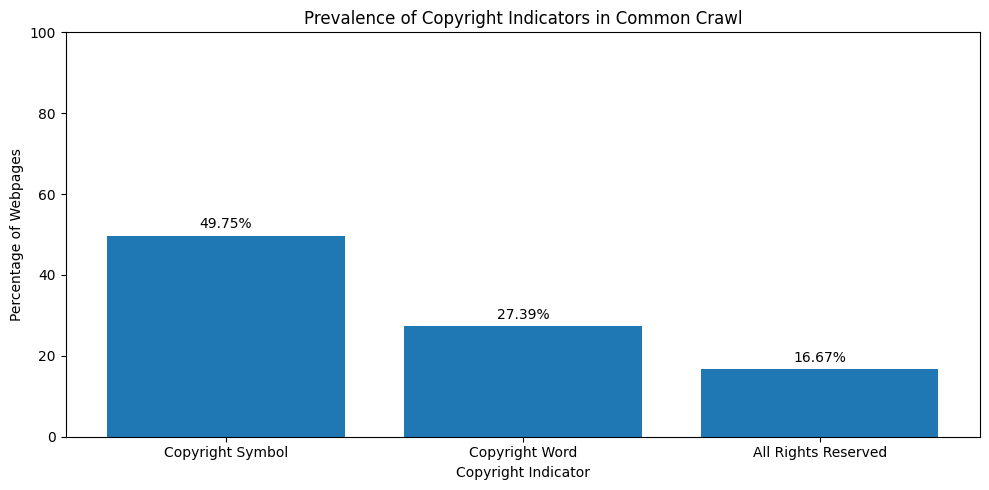

In [55]:
labels = ["Copyright Symbol","Copyright Word","All Rights Reserved"]

percentages = df[indicators].mean() * 100

plt.figure(figsize=(10, 5))

bars = plt.bar(labels, percentages)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Prevalence of Copyright Indicators in Common Crawl")
plt.ylabel("Percentage of Webpages")
plt.xlabel("Copyright Indicator")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

Bar chart showing percentage of Common Crawl webpages containing indicators. The copyright symbol appears most frequently wih nearly 50% of webpages containing it.

In [56]:
indicators = ["copyright_symbol","copyright_word","all_rights_reserved"]

df["has_copyright_indicator"] = (df[indicators].any(axis=1).astype(int))

Creating target variable has_copyright_indicator for logistic regression.

In [57]:
df["word_count"] = (df["webpage_text"].fillna("").str.split().str.len())

df["character_count"] = (df["webpage_text"].fillna("").str.len())

df["line_count"] = (df["webpage_text"].fillna("").apply(lambda text: len(text.splitlines())))

Here we look deeper into text length for each webpage including the number of words, number of characters including punctuation and symbols, and the total number of lines separating each text.

In [58]:
df["domain"] = df["url"].apply(lambda x: urlparse(str(x)).hostname or "")

df["domain_extension"] = df["domain"].str.split(".").str[-1]

df["url_length"] = df["url"].str.len()

df["is_https"] = (df["url"].str.startswith("https://", na=False).astype(int))

df = df[df["domain_extension"].str.len() > 2].copy()

Removes the country codes for the domain extensions for analysis on types of copyright material rather than by country.

In [59]:
features = [
    "word_count",
    "character_count",
    "line_count",
    "domain_extension",
    "url_length",
    "crawl_id",
]

display(df[features])

,word_count,character_count,line_count,domain_extension,url_length,crawl_id
0,92,897,85,com,31,CC-MAIN-2026-34
1,91,810,28,com,50,CC-MAIN-2026-34
2,468,7907,218,com,20,CC-MAIN-2026-34
3,54,362,7,com,18,CC-MAIN-2026-34
5,189,972,100,com,48,CC-MAIN-2026-34
...,...,...,...,...,...,...
9992,414,2047,103,com,122,CC-MAIN-2026-39
9993,6663,43868,364,com,97,CC-MAIN-2026-39
9995,1337,7861,143,com,64,CC-MAIN-2026-39
9996,66,426,42,org,108,CC-MAIN-2026-39


Here we create a list of features for regression to see if word count, chracter count, line count, domain, and length of url affect prevalence of copyright indicators.

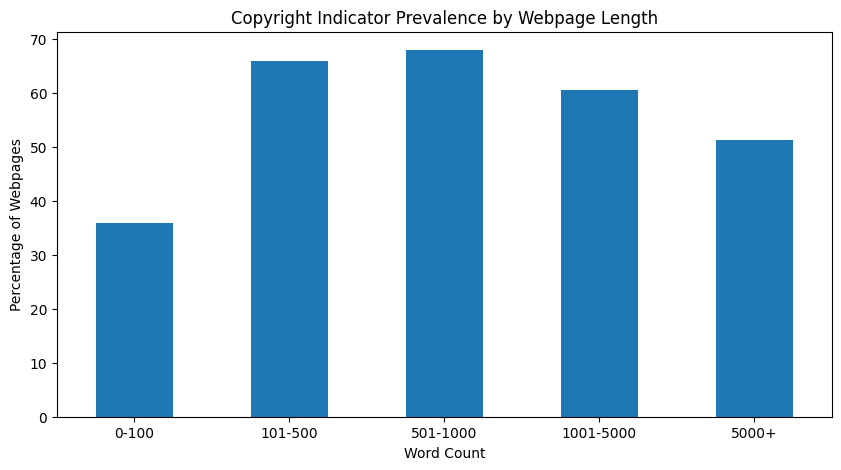

In [60]:
df["word_count_group"] = pd.cut(
    df["word_count"],
    bins=[-1, 100, 500, 1000, 5000, float("inf")],
    labels=["0-100","101-500","501-1000","1001-5000","5000+"])

length_summary = (
    df.groupby("word_count_group", observed=True)
    ["has_copyright_indicator"].mean() * 100)

length_summary.plot(
    kind="bar",figsize=(10, 5), title="Copyright Indicator Prevalence by Webpage Length")

plt.ylabel("Percentage of Webpages")
plt.xlabel("Word Count")
plt.xticks(rotation=0)
plt.show()

Bar char showing copyright indicator prevalence based on webpage length. This answers whether longer webpages are more likely to contain copyright indicators.

In [65]:
X = df[features]
y = df["has_copyright_indicator"]

X = pd.get_dummies(
    X,
    columns=["domain_extension", "crawl_id"],
    drop_first=True,
    dtype=int
)

display(X.head())

,word_count,character_count,line_count,url_length,domain_extension_121,domain_extension_140,domain_extension_143,domain_extension_161,domain_extension_166,domain_extension_182,...,domain_extension_wang,domain_extension_website,domain_extension_work,domain_extension_xin,domain_extension_xn--p1ai,domain_extension_xyz,domain_extension_yokohama,crawl_id_CC-MAIN-2026-34,crawl_id_CC-MAIN-2026-39,crawl_id_CC-MAIN-2026-43
0,92,897,85,31,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,91,810,28,50,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,468,7907,218,20,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,54,362,7,18,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5,189,972,100,48,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Define X as features and y as copyright indicators. Encode to convert categorical variables into numerical columns.

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [69]:
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

num_features = ["word_count", "url_length"]

X_train[num_features] = scaler.fit_transform(X_train[num_features])

X_test[num_features] = scaler.transform(X_test[num_features])

In [73]:
model = LogisticRegression(max_iter=2000, random_state=42)

model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=2000, random_state=42)

In [74]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print(classification_report(y_test, y_pred))

Accuracy: 0.5716814159292035
Precision: 0.5769603097773476
Recall: 0.926905132192846
F1 Score: 0.711217183770883
ROC-AUC: 0.5539645080011879
              precision    recall  f1-score   support

           0       0.52      0.10      0.17       487
           1       0.58      0.93      0.71       643

    accuracy                           0.57      1130
   macro avg       0.55      0.51      0.44      1130
weighted avg       0.55      0.57      0.48      1130



The model has 55% prediction performance showing that it is not very effective at identifying webpages with and without copyright indicators. The recall shows that the model tends to predict that webpages contain indicators when they do not.

In [76]:
coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0],
    "Odds Ratio": np.exp(model.coef_[0])
})

coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficient_df)

,Feature,Coefficient,Odds Ratio
20,domain_extension_biz,0.358613,1.431343
48,domain_extension_icu,0.352976,1.423297
63,domain_extension_net,0.271686,1.312175
31,domain_extension_com,0.252749,1.287560
90,domain_extension_top,0.196209,1.216781
...,...,...,...
43,domain_extension_fun,-0.189970,0.826984
98,domain_extension_xyz,-0.214078,0.807285
80,domain_extension_shop,-0.243915,0.783554
0,word_count,-0.333740,0.716240


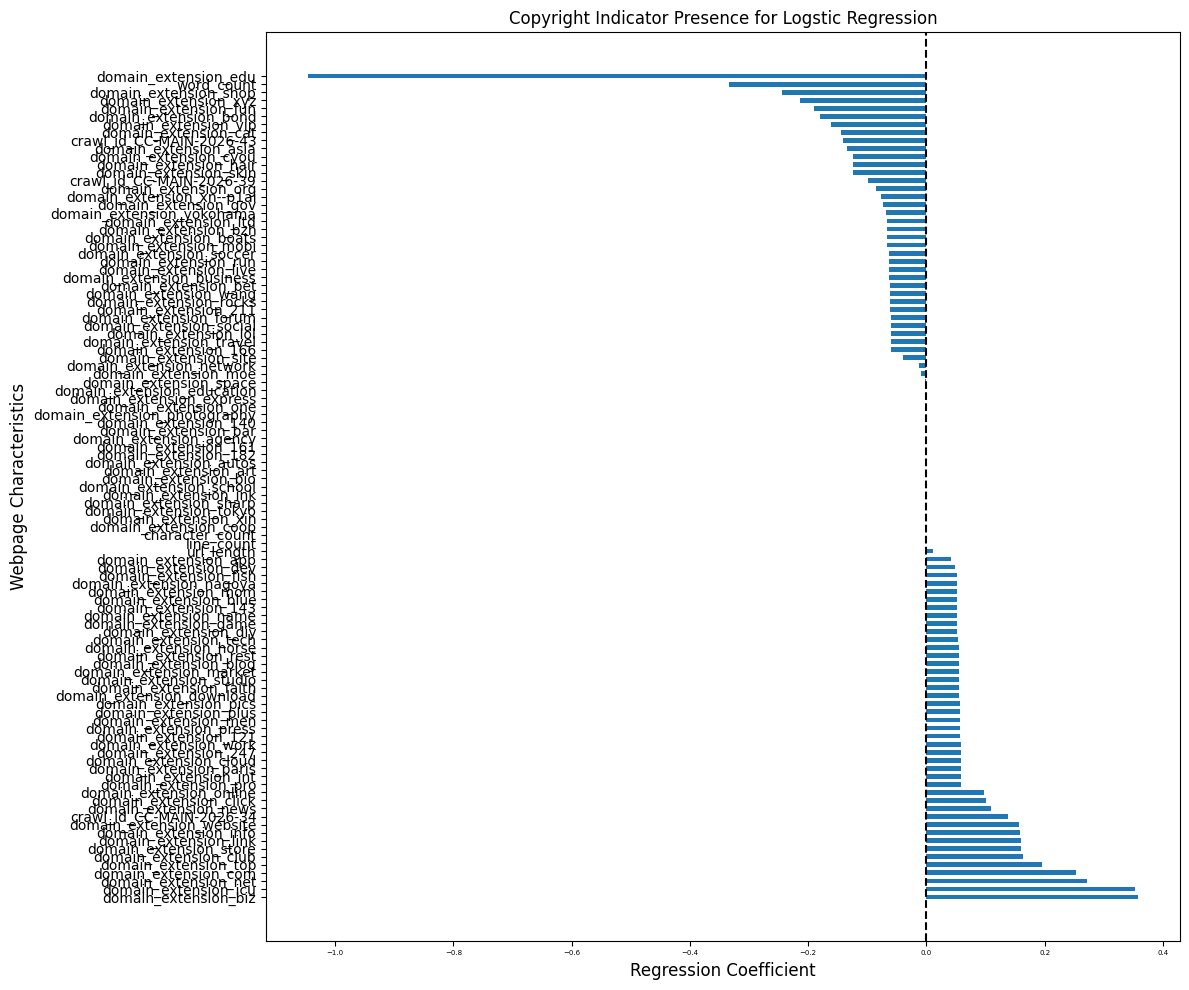

In [81]:
plt.figure(figsize=(12, 10))

plt.barh(coefficient_df["Feature"], coefficient_df["Coefficient"], height=0.6)

plt.axvline(0, color="black", linestyle="--")

plt.title("Copyright Indicator Presence for Logstic Regression")
plt.xlabel("Regression Coefficient", fontsize=12)
plt.ylabel("Webpage Characteristics", fontsize=12)

plt.yticks(fontsize=10)
plt.xticks(fontsize=5)

plt.tight_layout()
plt.show()

A graph of all domain extensions and the odds of containg copyright indicators.

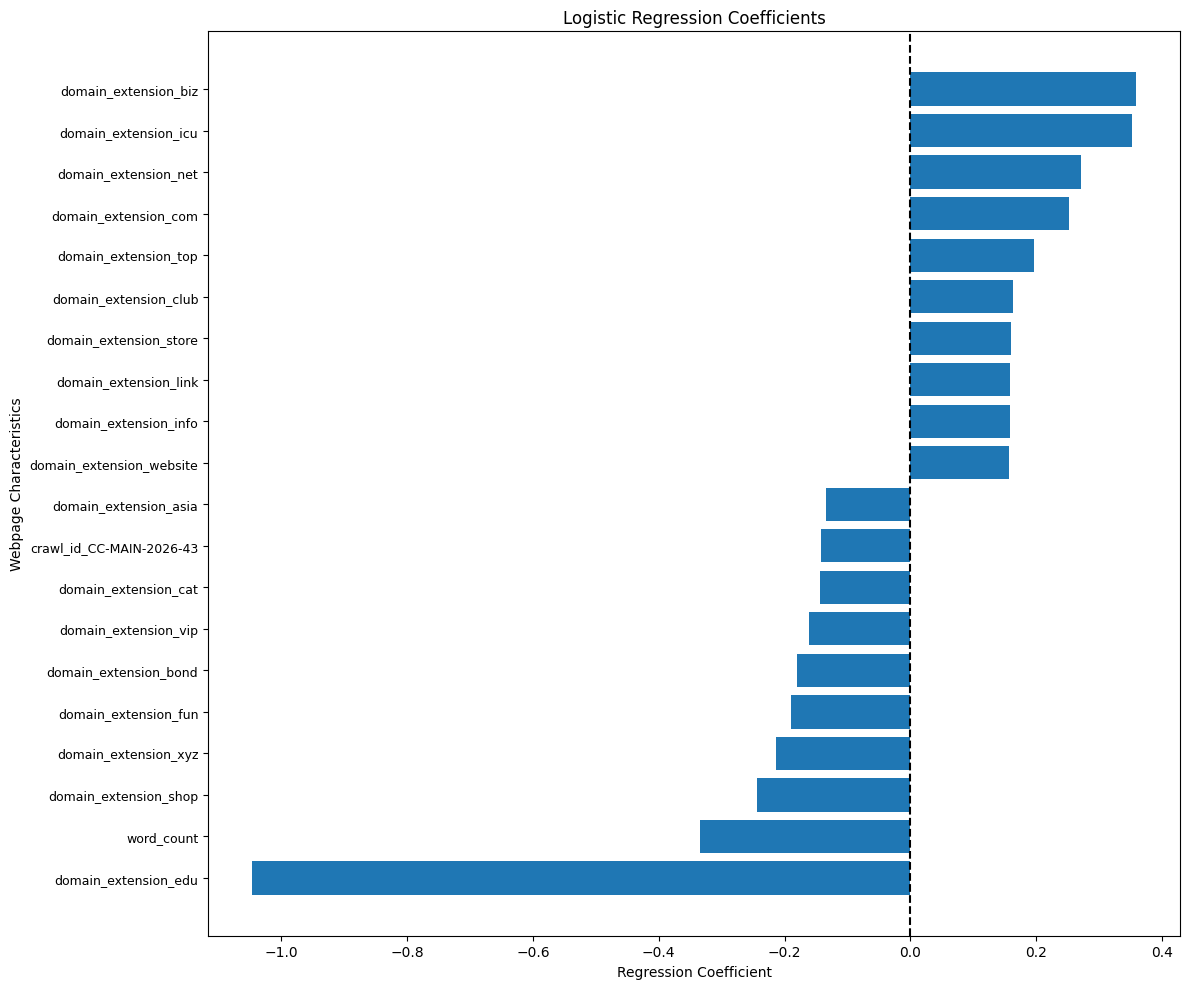

In [82]:
top_positive = coefficient_df.nlargest(10, "Coefficient")
top_negative = coefficient_df.nsmallest(10, "Coefficient")

top_coefficients = pd.concat([top_positive, top_negative])

top_coefficients = top_coefficients.sort_values("Coefficient")

plt.figure(figsize=(12, 10))

plt.barh(top_coefficients["Feature"], top_coefficients["Coefficient"])

plt.axvline(0, color="black", linestyle="--")

plt.title("Logistic Regression Coefficients")
plt.xlabel("Regression Coefficient")
plt.ylabel("Webpage Characteristics")

plt.yticks(fontsize=9)
plt.xticks(fontsize=10)

plt.tight_layout()
plt.show()

Graph showing the 10 highest and lowest domain extensions containing copyright indicators. The logistic regression results suggest that domain extensions with general purpose, websites, and business have higher odds of containing copyright indicators. Shopping and education have lower odds of containing copyright indicators.